# Movimientos en masa tipo flujos

## Objetivos de aprendizaje

Al finalizar este capítulo, el estudiante será capaz de:

- Distinguir entre flujos de detritos, avenidas torrenciales y otros tipos de movimientos en masa con componente fluida.
- Estimar la distancia de alcance (*runout*) de un flujo usando el ángulo de viaje (Fahrböschung) y la relación empírica de Corominas (1996).
- Describir los modelos de propagación disponibles (Flow-R, r.avaflow, FLO-2D) y sus datos de entrada requeridos.
- Comprender el impacto de las avenidas torrenciales en Colombia y los factores que incrementan su frecuencia.

**Duración estimada:** 2–3 horas

## Requisitos previos

- **Python:** `numpy`, `matplotlib` (para el modelo de runout).
- **Hidráulica/Hidrología:** flujo en canales, número de Froude, sedimento.
- **Geomorfología:** morfología de cuencas torrenciales, abanicos aluviales, procesos de transporte de masa.
- **Capítulos anteriores:** `07_detonante` (lluvia como detonante), `05_inventario` (inventario de flujos).

Aunque las avenidas torrenciales han sido un fenómeno común en Colombia, los estudios realizados al respecto son escasos. Probablemente una de las razones está asociada a la falta de un consenso con respecto a clasificación y terminología de fenómenos tipo flujos torrenciales que permita caracterizar adecuadamente qué son las avenidas torrenciales. La literatura técnica en inglés utiliza términos como *flash flood*, *debris flood*, *debris torrent* y *debris flow* para una gran cantidad de fenómenos de mezcla de agua y sedimentos que se transportan a lo largo de un cauce. Entre tanto en español existen términos como inundación súbita, avenida torrencial e incluso avalanchas para designar este tipo de fenómenos. 

En Colombia las avenidas torrenciales son entendidas como movimientos en masa o como crecientes súbitas, fenómenos aparentemente muy diferentes que implica el uso de métodos con enfoques diferentes. INGEOMINAS (2001) define las avenidas torrenciales como fenómenos de remoción en masa donde el agua de una corriente aumenta considerablemente su volumen por el transporte de material solido que ha caído a su cauce desde las laderas adyacentes. En este mismo sentido, Castro (1999) propone establecer el uso del término avenidas torrenciales como un flujo de escombros canalizado. La Guía para la Evaluación de Amenazas por Movimientos en Masa en la Región Andina (PMA-GCA, 2007) define las avenidas torrenciales como flujos de detritos (*debris flow*) de acuerdo con la definición de Hungr et al (2001). Por otro lado, en el marco de los Planes de Ordenación y Manejo de Cuencas (POMCA) las avenidas torrenciales son entendidas como inundaciones de tipo fluvial rápidas o torrenciales. La Guía Técnica para la Incorporación de la Gestión del Riesgo en los POMCA define las avenidas torrenciales como crecientes súbitas que por las condiciones geomorfológicas de la cuenca están compuestas por un flujo de agua con alto contenido de materiales de arrastre, con un gran potencial destructivo debido a su alta velocidad (MADS, 2014). El Fondo de Prevención y Atención de Emergencias de la ciudad de Bogotá (FOPAE) define las avenidas torrenciales como sinónimo de inundaciones rápidas generadas por crecientes que ocurren de manera repentina debido a la alta pendiente del río o la quebrada y su cuenca, donde en ocasiones se produce el arrastre de una gran cantidad de material como detritos (FOPAE, 2011).

Estas dos miradas sobre las avenidas torrenciales se reflejan en la *Guía Metodológica para la Evaluación de la Amenaza por Movimientos en Masa en Suelo Rural* del Servicio Geológico Colombiano (SGC). En esta guía las avenidas torrenciales se consideran equivalentes a los flujos de detritos y flujos de lodos descritos por el PMA-CGA (2007), pero adopta la definición de la guía de los POMCA como procesos tipo flujo que incluye eventos generados sobre ríos y quebradas de alta montaña y en cuencas con características geomorfológicas que favorecen la alta acumulación de sedimentos sobre el cauce, cambios drásticos en el gradiente del afluente, alta densidad de drenaje y eventos de precipitación (MADS & UNAL, 2013).

Estas dos miradas han dado como resultado metodologías con enfoques diferentes para evaluar la susceptibilidad o amenaza ante avenidas torrenciales. En la guía de los POMCA se propone el uso de índices morfométricos para evaluar la respuesta hidrológica de la cuenca, específicamente el Índice de Vulnerabilidad frente a Eventos Torrenciales (IVET), combinado con análisis geomorfológicos para evaluar el potencial aporte de sedimentos de la cuenca. Y en las guías que ha elaborado el SGC se han propuesto métodos estadísticos para evaluar la susceptibilidad por movimientos en masa sobre las laderas de la cuenca, como potencial aporte de sedimentos, combinado con análisis geomorfológico (Ingeominas, 1988; SGC, 2017). 

La reciente Guía metodológica para zonificación de amenaza por avenidas torrenciales del Servicio Geológico Colombiano, elaborada por la Pontificia Universidad Javeriana, adopta la definición de avenidas torrenciales como flujos rápidos que transitan por cauces permanentes o  intermitentes con pendientes longitudinales altas que puede ser generado por efecto de lluvias intensas. Término que comprende para los autores flujos de detritos, flujos de lodos y flujos hiperconcentrados. De esta forma proponen un esquema metodológico  que combina criterios geológico-geomorfológicos, análisis geotécnicos sobre las laderas para evaluar el potencial aporte de sedimentos por movimientos en masa y erosión laminar, análisis hidrológicos para estimar el factor detonante lluvia, y finalmente modelos fluidodinámicos de acuerdo con la reología, para propagar el flujo.   

Las diferencias entre fenómenos puramente hidrológicos y movimientos en masa están bien establecidas físicamente (Coussot and Meunier 1996; O’Brien and Julien 1985; Pierson and Costa 1987; Takahashi 1981); sin embargo, no existe unanimidad sobre definiciones específicas para flujos torrenciales que contienen una mezcla de agua y sedimentos en proporciones variables. De forma general, los flujos se definen como un fenómeno de transporte de sedimentos compuesto por una mezcla de material fino y grueso con una cantidad variable de agua, donde tanto las fuerzas sólidas como las fluidas influyen fuertemente (Iverson 1997; Nettleton et al. 2005). Según el tipo de proceso dominante y relación sedimentos-agua, esta mezcla es considerada desde procesos gravitacionales tipo flujo (Cruden and Varnes 1996) hasta procesos hidrológicos tipo inundaciones súbitas (NWS, 2005), donde en muchos casos el término flujo hiperconcentrado es utilizado para describir flujos intermedios entre estos dos fenómenos. 

Iverson (1997) distingue los procesos gravitacionales como aquellos donde las interacciones entre los fragmentos sólidos dominan la transferencia de momento, y las inundaciones cargadas de sedimentos como aquellas donde la turbulencia del fluido domina la transferencia de momento; para casos intermedios usa el término flujos de escombros, donde los sólidos y fluidos deben transferir el momento de forma sinérgica para sostener el movimiento. Takahashi (1981) distingue el transporte de sedimentos entre flujos fluidos y movimientos en masa, porque mientras que en los fluidos las fuerzas de arrastre y levantamiento, dadas por la alta velocidad relativa, son claves para el transporte individual de partículas, en los movimientos tipo caída, deslizamiento o flujos todas las partículas, así como el fluido intersticial, son movidos por la fuerza de la gravedad, de modo que la velocidad relativa entre la fase sólida y la líquida desempeña un papel menor. En este mismo sentido, Ancey (2001) distingue entre dos regímenes de flujo, flujos de dos fases, donde el agua es el agente principal y el pequeño porcentaje de sedimentos es transportado como carga de fondo y por suspensión; y flujos de una fase, compuestos por una mezcla altamente concentrada de sedimentos y agua. Sin embargo, Pierson (2005) propone que, además de la concentración de sedimentos suspendidos, la distribución del tamaño de granos y la densidad de los granos se debe utilizar para definir las mezclas sedimento-agua.

:::{figure-md} rheology
<img src="https://www.mdpi.com/symmetry/symmetry-10-00094/article_deploy/html/images/symmetry-10-00094-g001.png" alt="rheology" width="700px">

Reologia de flujos. Tomado de [Wang et al. (2018)](https://www.mdpi.com/2073-8994/10/4/94/htm).
:::

Diferentes autores han propuesto límites de concentración en peso y volumen para diferenciar flujos de agua con flujos hiperconcentrados y flujos de escombros. En general se proponen valores por encima del 30% en volumen para flujos hiperconcentrados, y valores por encima del 70% en volumen para flujos gravitacionales (Bradley 1986).

En terminos del origen, diferentes causas han sido descritas como detonantes de flujos torrenciales, Slaymaker (1988) divide los mecanismos detonantes como internos y externos. Los mecanismos externos se refieren a intensos o prolongados eventos de lluvia, sismos, enjambre de avalanchas de escombros o avalanchas de nieve (Miles 1957), rotura de presas naturales y su liberación instantánea (Takahashi 1981), y entre los mecanismos internos, Slaymaker (1988) resalta la desestabilización y removilización de los sedimentos del cauce.

En la literatura existen clasificaciones para procesos gravitacionales, donde se incluyen fenómenos tipo flujos de escombros canalizados (Cruden & Varnes 1996; Hutchinson 1988; Varnes 1978). Cruden and Varnes (1996) y Varnes (1978) clasifican los procesos gravitacionales de vertiente según el tipo de movimiento y los materiales. En estas clasificaciones, los flujos se definen como un movimiento espacialmente continuo en el que las superficies de cizallamiento son de corta duración, están poco espaciadas y generalmente no se conservan. De acuerdo con el tamaño del material, podrían denominarse flujos de tierra cuando las partículas son menores de 2 mm, o flujos de escombros cuando dominan las partículas de tamaño grueso. Hutchinson (1988) y Nettleton et al. (2005) distinguen dos formas de flujos de escombros: aquellos que forman su propio camino hacia abajo de las laderas del valle, flujos de escombros de laderas, y los flujos de escombros canalizados que siguen los canales existentes.

Existen tambien clasificaciones de flujos de escombros, en las que se utiliza el término para nombrar una mezcla de agua y sedimentos en diferentes proporciones (O’Brien & Julien 1985). Crosta et al. (1990) proponen usar el término flujos de escombros en un significado amplio, dividiéndolos en cuatro categorías: (i) Flujos de escombros no canalizados en drenajes de orden cero, originados como desgarres superficiales, (ii) Flujos de escombros en cuencas canalizadas de pendientes medias, originados como deslizamientos rotacionales o traslacionales, (iii) Avalanchas de escombros en intercuencas de pendientes mayores a 45°, (iv)  Torrente de escombros que se dan inicio en valles estrechos, causados por la falla o ruptura de presas generadas por deslizamientos, flujos de escombros o bloqueos de avalanchas de nieve.

:::{figure-md} flow-taxonomy
<img src="https://www.hec.usace.army.mil/confluence/rasdocs/rasmuddebris/files/43818444/43818446/1/1608274139824/worddavf90b29b9f53296a0e51b87e5f1a23fbc.png" alt="Flow axonomy" width="700px">

Taxonomía de flujos no Newtonianos con los modelos reológicos y ecuaciones utilizadas para modelar. Tomado de [Mud and Debris flow](https://www.hec.usace.army.mil/confluence/rasdocs/rasmuddebris/non-newtonian-user-s-manual/taxonomy-of-mud-and-debris-flows).
:::

Entre tanto, O’Brien and Julien (1985) proponen una clasificación para flujos de acuerdo con las propiedades controladas por la concentración de sedimentos, cuya clasificación va desde inundaciones hasta movimientos en masa. Los autores identifican cinco categorías de flujos: (i) Crecientes: Definidos como inundaciones de agua por descargas excesivas donde los sedimentos son transportados a través de suspensión y saltación por el lecho, (ii) Inundaciones de lodo: Flujos donde la concentración de sedimentos finos varía de 20 a 45% por volumen, (iii) Flujos de lodo: Flujos donde la concentración de sedimentos finos varía de 45 a 50% por volumen, (iv) Flujos de escombros: Aplicado a flujos de lodo con más del 50% de sedimentos más gruesos que arena, (v) Deslizamientos: Movimiento en masa donde la concentración por volumen de sedimentos es mayor al 50%.

Coussot & Meunier (1996) proponen una clasificación en función de la concentración de sedimentos y el tipo de material, la cual varía desde flujos de corriente, donde los sedimentos son transportados por suspensión y carga de fondo hasta deslizamientos. Como términos intermedios entre estos dos fenómenos se encuentran los flujos hiperconcentrados, flujos de lodo, flujos de escombros y flujos granulares.  

Iverson (1997) incluye dentro de la categoría de flujos de escombros una gran cantidad de fenómenos como deslizamientos de escombros, torrentes de escombros, inundaciones de escombros, flujos de lodo, deslizamientos de lodo, y lahares para flujos de escombros de origen volcánico. 

Pierson & Costa (1987) proponen una clasificación de mezclas sedimento - agua basada en la concentración de sedimentos y la velocidad media del flujo, y dividen los flujos en dos tipos diferentes: (i) Flujos líquidos aparentes: caracterizados por tener pequeñas concentraciones de sedimentos, divididos a su vez en flujos de corriente, para flujos donde el agua es la fase continua, y flujos de corrientes hiperconcentrados, para flujos donde la mezcla de agua y sedimentos presenta un límite elástico medible, pero aún parece fluir como un líquido. (ii) Fluidos plásticos: donde hay una mayor concentración de sedimentos, divididos en flujos de lodo y flujos granulares de acuerdo con el tamaño de los sedimentos. 

Hungr et al. (2001) y Oldrich Hungr, Leroueil, & Picarelli (2014) proponen una clasificación de movimientos en masa tipo flujo donde incluyen el término inundación súbita como sinónimo de inundación de escombros, y lo definen como un flujo de agua muy rápido, fuertemente cargado con detritos en un canal de alta pendiente, y un caudal pico comparable a las inundaciones. En estos tipos de flujos el lecho de los cauces puede ser desestabilizado con el transporte masivo de sedimentos que excede el movimiento de fondo normal a través de la suspensión y saltación, pero que aún depende de las fuerzas de tracción del agua. Estos autores diferencian los eventos tipo inundación súbita de fenómenos tipo flujo de escombros, ya que estos últimos están limitados en canales o drenajes de primer y segundo orden de fuerte pendiente con áreas que alcanzan solo unos pocos kilómetros cuadrados y el volumen principal se da por el arranque y arrastre a lo largo de su recorrido, mientras que los eventos tipo inundación súbita, debido al arrastre del agua, pueden ocurrir en cuencas mucho más grandes y los depósitos se extienden sobre distancias mayores y áreas de menores pendientes. Como parte de eventos tipo inundación súbita incluyen los flujos generado por la ruptura repentina de lagos glaciales, denominados GLOFs (Glacial Lake Outburst Floods).

Otras clasificaciones de mezclas de sedimentos y agua usan el término inundación súbita en un sentido general, para denominar flujos de alta descarga en corrientes que drenan cuencas hidrográficas pequeñas y de fuerte pendiente. El Servicio Geológico de los Estados Unidos (USGS por sus siglas en ingles), basado en Crosta et al. (1990) y Jakob & Hungr (2005), dividen las inundaciones súbitas en tres tipos de flujos: flujos de agua, flujos hiperconcentrados y flujos de escombros. En los flujos de agua, la cantidad de sedimento suspendido es insuficiente para afectar el comportamiento del agua, mientras que en los flujos hiperconcentrados la cantidad de sedimentos cambia significativamente las propiedades del fluido y los mecanismos de transporte, y los flujos de escombros se consideran cuando la mezcla de agua y sedimentos se convierte en una mezcla capaz de soportar partículas de tamaño grava en suspensión incluso a baja velocidad o estático. Gaume et al. (2009) utilizan la misma clasificación del USGS para clasificar las inundaciones súbitas que ocurren en Europa, pero proponen usar el término inundación de escombros en lugar de flujos hiperconcentrados.

En cuanto a los flujos tipo torrentes de escombros, considerados por diferentes autores en sus clasificaciones, Aulitzky (1980) los diferencia entre torrentes de flujo de escombros y torrentes de flujo de lodos, donde los torrentes de flujos escombros, considerados como una forma de flujos de escombros canalizados cuando se presentan como resultado de enjambre de movimientos en masa (Sterling and Slaymaker 2007), corresponden a flujos viscosos no newtonianos con pulsos y velocidades que alcanzan los 30 m/s, y los torrentes de inundación de escombros como flujos viscosos sin pulsos y que alcanzan velocidades menores y menor capacidad de transporte, que se caracterizan por la ausencia de material fino, y la presencia de escombros de origen orgánico y grandes dimensiones (Slaymaker, 1988).

Todas estas clasificaciones de mezclas de agua y sedimentos tienen una escala continua de estos dos materiales; sin embargo, no incluyen un término que pueda traducirse literalmente como avenida torrencial. Por el contrario, utilizan diferentes términos como inundación súbita, flujo de escombros, inundación de escombros, torrente de escombros, los cuales son correlacionables según las descripciones proporcionadas a fenómenos descritos en nuestro país como avenidas torrenciales. 

Un caso reciente y ampliamente documentado de este tipo de fenómeno en Colombia corresponde al evento de Mocoa (Putumayo) ocurrido el 31 de marzo de 2017, detonado por una lluvia intensa de corta duración precedida de una alta precipitación antecedente que saturó los materiales de ladera; el periodo de retorno estimado para el evento de lluvia detonante se ubica entre 25 y 50 años. En las guías de amenaza a escala 1:25.000 elaboradas para esta cuenca, las zonas de alta susceptibilidad cubren aproximadamente el 20,4% del área de estudio (872 ha), y se modela que una tormenta de esta magnitud, bajo condiciones de saturación completa, puede generar densidades de hasta 46 movimientos en masa por kilómetro cuadrado. Precisamente por la dificultad de extrapolar directamente escenarios de cambio climático a escalas y resoluciones específicas de modelos de actividad de movimientos en masa, el Servicio Geológico Colombiano recomienda que tanto los umbrales regionales de lluvia-movimientos en masa como el diseño de obras estructurales de mitigación (diques, presas de retención, muros) incorporen explícitamente los escenarios proyectados de cambio climático y los cambios de uso del suelo de origen antrópico.

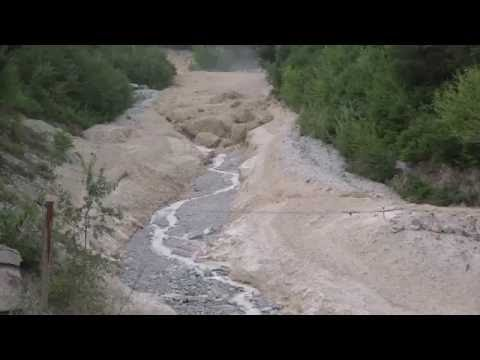

In [1]:
from IPython.lib.display import YouTubeVideo
YouTubeVideo('0ENe7wDKP6I')

Actualmente existe una gran variedad de modelos que permiten evaluar la propagación de un volumen de material a lo largo de terreno. En términos de modelos con base física, estos difieren en el grado de complejidad de la reología del flujo y la cantidad de parámetros requeridos. A continuación se presentan dos modelos que constrastan. El modelo *Flow-R*, que requiere solo el modelo digital del terreno, y el modelo *r.ava.flow*, el cual tiene la capacidad de modelar diferentes tipos de flujos de 1, 2 ó 3 fases.

## Implementación: Estimación de Runout — Ángulo de Viaje (Fahrböschung)

El **ángulo de viaje** o *Fahrböschung* (H/L) es el método empírico más utilizado para estimar la distancia de alcance (*runout*) de flujos y deslizamientos (Corominas, 1996). Se define como:

$$\tan\alpha = \frac{H}{L}$$

donde $H$ es la diferencia de elevación entre el punto de inicio y el depósito, y $L$ es la distancia horizontal total recorrida. Los valores típicos varían según el tipo de movimiento:

| Tipo de movimiento | $\tan(\alpha)$ típico | Runout relativo |
|-------------------|----------------------|-----------------|
| Avalancha de roca | 0.10 – 0.20 | Muy largo |
| Flujo de detritos | 0.20 – 0.40 | Largo |
| Deslizamiento traslacional | 0.40 – 0.70 | Moderado |
| Caída de roca | > 0.70 | Corto |

Corominas (1996) propuso relaciones empíricas de la forma $\log(L) = a + b\cdot\log(V)$, donde $V$ es el volumen del movimiento.

De forma más específica, Corominas (1996) reporta coeficientes de regresión distintos según el tipo de movimiento y las condiciones del recorrido (trayectoria obstruida o sin obstruir): para flujos de detritos, combinando todas las trayectorias, $a=-0,012$ y $b=-0,105$ ($R^2=0,76$), valores que mejoran a $a=-0,031$, $b=-0,102$ ($R^2=0,87$) cuando la trayectoria no está obstruida; para deslizamientos traslacionales, $a=-0,159$ y $b=-0,068$ ($R^2=0,67$) combinando todas las trayectorias; y para caídas de roca, $a=0,210$ y $b=-0,109$ ($R^2=0,76$). Como referencia general e independiente del tipo de movimiento, el propio Corominas (1996) reporta un coeficiente promedio global de $a=-0,047$ y $b=-0,085$, con un coeficiente de correlación $R=0,79$. Estas diferencias evidencian que, a igual volumen desplazado, los flujos de detritos y deslizamientos traslacionales tienden a presentar un alcance relativo mayor que las caídas de roca, y que el grado de confinamiento del cauce o la ladera (obstruido vs. sin obstruir) modifica sustancialmente la calidad del ajuste estadístico de la relación runout-volumen.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ── Modelo 1: Ángulo de viaje (Fahrböschung) ─────────────────────────────────
def runout_angulo_viaje(H, tan_alpha):
    """
    Estima la distancia de alcance horizontal a partir del ángulo de viaje.

    Parámetros
    ----------
    H         : diferencia de altura entre inicio y depósito [m]
    tan_alpha : tangente del ángulo de viaje (H/L típico)

    Retorna
    -------
    L : distancia de runout horizontal [m]
    """
    return H / tan_alpha

# ── Modelo 2: Relación empírica volumen-runout (Corominas, 1996) ──────────────
def runout_corominas(V_m3, tipo='flujo_detritos'):
    """
    Estima L/H a partir del volumen del movimiento (Corominas, 1996).
    Coeficientes para flujo de detritos: log(L/H) = 0.581 + 0.162*log(V)

    Parámetros
    ----------
    V_m3 : volumen del movimiento [m³]
    tipo : tipo de movimiento (para futuras extensiones)

    Retorna
    -------
    LH : relación L/H (adimensional)
    """
    # Coeficientes para flujos de detritos (Corominas, 1996)
    a, b = 0.581, 0.162
    return 10 ** (a + b * np.log10(V_m3))

# ── Ejemplo: Avenida torrencial — Cuenca La Liboriana (Salgar, 2015) ──────────
H        = 1800   # desnivel aproximado [m]
V_est    = 5e5    # volumen estimado [m³]
tan_alph = 0.25   # ángulo de viaje típico para flujo de detritos

L_angulo    = runout_angulo_viaje(H, tan_alph)
LH_corominias = runout_corominas(V_est)
L_corominas = LH_corominias * H

print('=== Estimación de Runout — Flujo de Detritos ===')
print(f'H = {H} m,  V = {V_est:.0e} m³')
print(f'Método ángulo de viaje (tan α={tan_alph}): L ≈ {L_angulo:.0f} m')
print(f'Método Corominas (1996):                   L ≈ {L_corominas:.0f} m')

# ── Análisis de sensibilidad: runout vs volumen ───────────────────────────────
volumenes = np.logspace(2, 7, 100)  # 100 m³ a 10,000,000 m³
LH_vals   = runout_corominas(volumenes)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Panel izquierdo: L/H vs Volumen
axes[0].loglog(volumenes, LH_vals, 'b-', lw=2)
axes[0].scatter([V_est], [LH_corominias], color='red', s=100, zorder=5,
                label=f'Liboriana: V={V_est:.0e} m³\nL/H = {LH_corominias:.1f}')
axes[0].set_xlabel('Volumen V [m³]', fontsize=12)
axes[0].set_ylabel('Relación L/H (adimensional)', fontsize=12)
axes[0].set_title('Relación Empírica Volumen – Runout\n(Corominas, 1996 — Flujos de Detritos)',
                  fontsize=12)
axes[0].legend(fontsize=10)
axes[0].grid(True, which='both', alpha=0.3)

# Panel derecho: perfil longitudinal esquemático
x = np.array([0, L_angulo])
y = np.array([H, 0])
axes[1].fill_between([0, L_angulo], [H, 0], alpha=0.3, color='saddlebrown',
                     label='Zona de deposición')
axes[1].plot(x, y, 'k-', lw=2)
axes[1].annotate('', xy=(L_angulo, 0), xytext=(0, H),
                 arrowprops=dict(arrowstyle='->', color='red', lw=2))
axes[1].text(L_angulo/2, H/2 + 50, f'α = arctan({tan_alph}) = {np.degrees(np.arctan(tan_alph)):.0f}°',
             ha='center', fontsize=11, color='red')
axes[1].set_xlabel('Distancia horizontal L [m]', fontsize=12)
axes[1].set_ylabel('Elevación H [m]', fontsize=12)
axes[1].set_title(f'Perfil de Runout — Ángulo de Viaje\n'
                  f'L = {L_angulo:.0f} m,  H = {H} m', fontsize=12)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## Flow-R

[Flow-R](https://www.flow-r.org/) (Flow path assessment of gravitational hazards at a Regional scale) es un modelo empírico distribuido para la evaluación de la susceptibilidad por flujos a escala regional, desarrollado por {cite:t}`horton2013` de la Universidad de Laussane. Flow-R presenta un acercamiento simplificado sin una gran exigencia de parámetros.

:::{figure-md} flow-R
<img src="https://www.researchgate.net/profile/Michel-Jaboyedoff/publication/258806561/figure/fig4/AS:614112920887296@1523427338200/Illustration-of-the-4-different-layers-of-processing-of-the-propagation-and-their_Q320.jpg" alt="Flow-R" width="400px">

Modelo Flow-R (https://www.flow-r.org/).
:::

Flow-R estima la propagación de los flujos mediante un balance energético básico y una propagación probabilística. Los algoritmos de la dirección de flujo calculan la probabilidad de que un flujo de detrito se mueva de una celda hacia las próximas 8 celdas. Estas probabilidades dependen de la pendiente y la persistencia que representa la inercia del flujo.

:::{figure-md} flow-R1
<img src="https://geotechpedia.com/Images/Software/Flow_-_R_software.jpg" alt="Flow-R1" width="500px">

Modelo Flow-R (https://www.flow-r.org/).
:::

### Tutorial
*Elaborado por María Isabel Arango*

El modelo Flow-R se puede utilizar para modelar:
* Las fuentes de flujos (zonas inestables)
* La propagación de flujos

El modelo que utiliza Flow-R para determinar las fuentes de flujos es un método heurístico basado en índices. Ya que existen otras herramientas que se describen en el presente libro; en esta guía solo se utilizará el componente de propagación. Por lo que para modelar utilizaremos solamente un modelo de elevación digital ([DEM](https://github.com/edieraristizabal/CartografiaGeotecnica/blob/master/libro/data/arenosa/dem_arenosa_clip.asc?raw=true)) y un mapa de las fuentes o [movimientos en masa](https://raw.githubusercontent.com/edieraristizabal/CartografiaGeotecnica/master/libro/data/arenosa/release.asc?raw=true) a propagar de la cuenca de la quebrada La Arenosa en el municipio de San Carlos (Antioquia). 

#### *Working directories*
Para ingresar la información al programa, se debe crear primero el proyecto y las carpetas en las cuales se almacenarán los datos de entrada y de salida. Siga los siguientes pasos:
* Cree en su computador la carpeta *La Arenosa FlowR*. Dentro de ella, cree dos carpetas: una que se llame *Datos* y otra que se llame *Resultados*.
* Abra el ejecutable de Flow-R. Se puede descargar de la página web https://www.flow-r.org/download. Después de llenar el formulario, el instalador le será enviado vía e-mail. Debe tener MATLAB ó su compilador instalado. Lo puede descargar de la página https://la.mathworks.com/products/compiler/matlab-runtime.html.
* Una vez abierto, seleccione en *Directory to store data* la carpeta *Datos*. En la sección *Directory to store resulting files*, seleccione la carpeta *Resultados*.

#### Ingresar los datos
* Seleccione en la pestaña de la parte superior de la interface Tools > Format Data > Import Data. Seleccione el archivo *DEM_Arenosa.asc*. Le aparecerá una advertencia mostrando el tipo de información que entiende el modelo > OK. 
* En la ventana siguiente, debe seleccionar el tipo de información que está ingresando. En este caso, seleccione la primera opción (DEM). Asígnele un nombre al DEM y seleccione para este caso la zona de proyección UTM 18N, que corresponde al noroccidente de Colombia. 
* Realice el mismo procedimiento para *release.asc* (importar como predefined sources). Asígnele un nombre. 
* Cuando termine de importar los raster, en la pestaña *Determination of the case study area* debe definir su zona de estudio. Usted puede ingresar un DEM de una zona grande en la cual quiere analizar una o varias zonas pequeñas. No es la opción más recomendable, pues el tiempo de procesamiento normalmente se hace mayor. Si a pesar de esto lo desea hacer, puede seleccionar cada una de las zonas de estudio y darle un nombre. Dado que en este ejercicio se analizará toda la cuenca de la Arenosa, que corresponde al DEM completo, seleccione *Select the whole DEM*. Llame a la zona de estudio *Toda*. Fíjese que en caso de querer, puede seleccionar la zona de estudio manualmente, dando unas coordenadas o a través de un raster que la delimite. Usted puede crear tantas zonas de estudio como desee.
* En la ventana de importación de datos, también están disponibles las opciones para la identificación de ríos y la selección de un búfer. Estas opciones son útiles en caso de que queramos reducir la búsqueda de áreas fuente a cierta distancia de las quebradas. Dado que no se limitará la búsqueda en este ejercicio, no ingrese nada en esa parte.
* Cierre la ventana de importación de datos
* En el campo *Choice of the study área*, seleccione la zona “Toda”, y en el campo *Choice of the rivers layer* seleccione *Toda_no_river*, que significa que no utilizará la información de las quebradas. Finalmente, asígnele en *Enter run name* un nombre a su corrida. Con este nombre se creará una subcarpeta en *Resultados* donde se guardarán los resultados de su modelación.
* **Recomendación**: *Asígnele un número y en una hoja relacione este número con los parámetros de los algoritmos que utilizó en dicha corrida. De tal forma que pueda trabajar ordenadamente las multiples modelaciones que seguramente realizará*.

#### *Source areas*
En esta parte se va a calcular la propagación del área fuentes definidas como zonas inestables que se propagarán en forma de flujo. Para esto, utilizará una fuente elaborada para este ejercicio, pero que no corresponde a un caso real. Dado que la única información necesaria para el cálculo de la propagación de flujos son el DEM y las fuentes predeterminadas, en la parte inferior izquierda *Source areas* ingrese estas dos capas únicamente. En la primera columna debe ingresar el tipo de información (*DEM*, *Predefined sources*), en la segunda columna el nombre del raster (estos corresponde a los nombres asignados al ingresar las capas), y en la tercera debe ingresar los criterios de lectura del archivo, *avove_0000m* para el DEM y *boolean* para las fuentes, respectivamente.

En la parte inferior *Source value* deje seleccionada la opción *Binary (0/1)*, ya que en este caso estamos trabajando con una mapa de fuentes tipo binario, donde celdas con valor de 0 es no movimientos en masa y celdas con valor 1 son movimientos en masa para propagar.

#### *Propagation*
En el panel derecho de la interfaz *Propagation* seleccione la pestaña *Propagation calculation*. Sobre la parte derecha se encuentran dos opciones *Sum of probabilities* y *Connected areas* que le brindan resultados adicionales. Para este ejemplo no las seleccione.

Posteriormente se deben ingresar todos los parámetros de los algoritmos para el cálculo de la dirección de propagación, extensión del flujo, y la metodología a usar para realizar los cálculos. Estos parámetros se describen a continuación:

**Calculation method > Source areas selection**: Se refiere al criterio a utilizar a la hora seleccionar cuáles celdas consideradas como áreas fuentes se utilizarán para el cálculo de la propagación. 

*Overview - Only superior sources*: Dado que son las áreas fuentes más altas las que tienen más energía potencial para propagarse, sólo se calculará la propagación para estas zonas, asumiendo que toda zona fuente ubicada debajo no llegará tan lejos. Es el método de cálculo más rápido pero no el más completo, dado que áreas fuente más bajas pueden tomar trayectorias diferentes a las calculadas.

*Quick – Energy based discrimination*: Las fuentes ubicadas en las zonas más altas se propagan primero. Luego, se consideran otras zonas fuentes, y si durante el cálculo en curso la propagación toma la misma trayectoria que una ya calculada con una energía similar o superior, los cálculos de la propagación actual se detienen ya que será redundante. Esta selección según la energía es muy eficiente, puede ahorrar mucho tiempo y produce resultados casi similares a la simulación completa para cada fuente. Es la opción más recomendable. Selecciónela.

*Complete – Simulation of all propagations*: Cada celda identificada como fuente se propaga. Este proceso es el más demorado, pero es útil en casos donde se requiera conocer la suma de los valores de probabilidad o de susceptibilidad. 

**Spreading algorithm > Directions Algorithm**: Se refiere al algoritmo que se usará para calcular la dirección que tomará el flujo. En este caso, utilizaremos el algoritmo de Holgrem modificado. En la lista desplegable, se deben seleccionar los valores que se le desean dar a dos variables:

*dH*: Exageración de la altura de la celda del cálculo en curso

*Exponente*: Se refiere al exponente de la ecuación.

Para escoger los valores óptimos de estos dos parámetros, es necesario realizar un proceso de calibración para la zona de estudio. Seleccione en este caso la primera opción, con valores de dh y exp de 0.5m y 0.1, respectivamente.

**Spreading algorithm > Inertial algorithm**: Se refiere al algoritmo a utilizar para forzar al modelo a fluir correctamente, evitando cambios de dirección bruscos y errores de computación como las propagaciones en contra de la pendiente. Use el algoritmo de pesos (*weights* y en la celda siguiente *Gamma 2000*, el cual le asigna a la celda en la dirección del flujo un mayor peso. 

**Energy calculation > Friction loss Function**: Algoritmo utilizado para calcular la energía del flujo, que determinará qué tan lejos llegará. Use el algoritmo de Perla et al (1980), que tienen cuenta dos variables:

*M/D*: Relación mass-to-drag 

*µ*: Coeficiente de fricción

Los valores óptimos de estos valores deben ser calibrados también para cada zona de estudio. Seleccione en este caso la primera opción, con valores de md y mu de 10 y 0.01, respectivamente.

Si se tienen estudios de la zona de interés relacionada con la velocidad máxima alcanzada por flujos en eventos pasados, se puede indicar ese valor en el campo “Energy limitation”, para evitar que los flujos tomen velocidades irreales, y que en consecuencia se propaguen más de lo que lo harían en la realidad. Dado que no se cuenta con información de este tipo para la zona de estudio, deje la celda vacía. 

* Finalmente, asegúrese de activar los campos *Display source áreas*, y *Display the propagation extent*
* Haga click sobre el botón “Run”
* Inmediatamente aparecerá una primera ventana mostrando las áreas fuentes en el mapa, y luego otra ventana mostrando el proceso de cálculo. Usted sabrá que el cálculo de la propagación terminó porque aparecerá una tercera ventana con los resultados de la propagación. 
* Para ver el mapa resultante consulte la subcarpeta con el nombre asignado por usted dentro de la carpeta *Resultados*, puede abrir el raster *Ekin.asc* que muestra la propagación del flujo en función de su energía cinética, o  el raster *ProbMax.asc*, que muestra la propagación en función de la probabilidad máxima de una celda de ser cubierta por un flujo. También en esta subcarpeta se crea un archivo con las áreas fuentes utilizadas y un archivo *xml* con los parámetros utilizados en la modelación.


## r-avaflow

r.avaflow es un modelo abierto y libre, desarrollado por {cite:t}`mergili2017`, para simular la dinámica de flujos rápidos, que incluye avalanchas y flujos de escombros. El modelo se soporta en un ambiente SIG, que permite modelar una gran variedad de escenarios, pero sin embargo también permite modelar escenarios con un mínimo de datos. Como mínimo se requiere sólo un modelo de elevación digital y un mapa con los espesores del área fuente en mapas raster formato *ASCII*. El modelo permite simular flujos con reologías diferentes: una fase, dos fases, y mezcla; además permite incorporar la erosión del flujo e incorporación de material a lo largo del canal. r.avaflow también permite incorporar en la modelación hidrografas de flujos variados.

Como resultado el modelo arroja la distribución espacial de la altura del flujo, velocidades y presiones, así como tiempos de llegada e hidrógrafas en puntos de control especificados en el modelo.

:::{figure-md} r.avaflow
<img src="https://www.landslidemodels.org/symbols/logo_avaflow.png" alt="r.avaflow" width="100">

Modelo r.avaflow (https://www.landslidemodels.org/r.avaflow).
:::

### Tutorial

*Elaborado por Juan Diego Torres, Luisa Fernanda Cardona, y Daissy Herrera*

En este tutorial se utilizará la versión para windows r.avaflow.direct, la cual posee una interfaz que facilita el ingreso de los parámetros al modelo. Se puede acceder a esta interfaz mediante [https://www.landslidemodels.org/r.avaflow/direct.php](https://www.landslidemodels.org/r.avaflow/direct.php).

Adicionalmente se debe contar como mínimo con un modelo de elevación digital formato *ASCII*, en este caso utilizaremos [La Arenosa](https://github.com/edieraristizabal/CartografiaGeotecnica/blob/master/libro/data/arenosa/DEM_Arenosa_Clip.asc?raw=true), y un archivo con las celdas fuentes que se deslizan y la profundidad, también en formato *ASCII*, para este caso denominado [release](https://github.com/edieraristizabal/CartografiaGeotecnica/blob/master/libro/data/arenosa/release.asc?raw=true). También se puede ingresar el área del depósito generado por el flujo, de tal forma que se pueda evaluar la capacidad de predicción del modelo.

**1- Para el uso del modelo r.avaflow se debe tener instalado los siguientes programas:**

* Sistema operativo Windows 10/11
* [r.avaflow.exe](https://www.landslidemodels.org/r.avaflow/software/r.avaflow.exe)
* [cyqwin1.dll](https://www.cygwin.com/)

Para visualizar los datos se debe contar con:

* [R project](https://www.r-project.org/)
* [paraview](https://www.paraview.org/)

**2- Importar parámetros**

En caso de disponer un archivo *.txt* con los parámetros este puede ser importado. Para este ejercicio se utilizarán cinco archivos con los parámetros. cada uno de ellos representa un escenario de modelación diferente:

* [areno1_paramraw](https://github.com/edieraristizabal/CartografiaGeotecnica/blob/master/libro/data/arenosa/areno1_paramraw.txt?raw=true): Archivo de texto que contiene todos los parámetros para el modelo de Pudasaini donde se estudia solo la fase sólida del movimiento.
* [areno2_paramraw](https://github.com/edieraristizabal/CartografiaGeotecnica/blob/master/libro/data/arenosa/areno2_paramraw.txt?raw=true): Archivo de texto que contiene todos los parámetros para el modelo de Fermi dónde se estudia el movimiento en conjunto, es decir, se tratan las fases sólidas y líquidas como una única fase (*mixture model*).
* [areno3_paramraw](https://github.com/edieraristizabal/CartografiaGeotecnica/blob/master/libro/data/arenosa/areno3_paramraw.txt?raw=true): Archivo de texto que contiene todos los parámetros para el modelo Pudasaini donde se estudia la fase sólida y líquida del movimiento.
* [areno4_paramraw](https://github.com/edieraristizabal/CartografiaGeotecnica/blob/master/libro/data/arenosa/areno4_paramraw.txt?raw=true): Archivo de texto que contiene todos los parámetros para el modelo de Fermi dónde se estudia el movimiento en conjunto, es decir, se tratan las fases sólidas y líquidas como una única fase; y se agrega una [hidrógrafa](https://github.com/edieraristizabal/CartografiaGeotecnica/blob/master/libro/data/arenosa/areno_hydrograph.txt?raw=true). Este archivo de texto indica el caudal y velocidad de la fase sólida, liquida o mezcla que representa el movimiento, en la hidrógrafa mostrada anteriormente, el índice *s*, alude a la fase sólida, *fs* a la fase fina y *f* a la fase líquida. Para esto se debe ingresar las coordenadas de ingreso de la hidrografa, para en este escenario se identificó el punto [893332, 1171629, 10, 225] donde los dos primeros valores son las coordenadas x, y, el tercer valor es el ancho del perfil del cauce y el cuarto valor es la dirección del flujo medido desde una línea oeste-este en sentido antihorario. Este archivo debe almacenarse en la carpeta de trabajo, donde se encuentran los parámetros.
* [areno5_paramraw](https://github.com/edieraristizabal/CartografiaGeotecnica/blob/master/libro/data/arenosa/areno5_paramraw.txt?raw=true): Archivo de texto que almacena los parámetros para un modelo multifase de fase sólida y líquida, utilizando una [hidrógrafa](https://github.com/edieraristizabal/CartografiaGeotecnica/blob/master/libro/data/arenosa/areno_hydrograph.txt?raw=true) y se incorpora dentro de la modelación la erosión del flujo sobre el cauce. Para que este caso corra correctamente se debe de definir un mapa de arrastre máximo para la fase sólida, denominado en este caso [are_hentmax1.asc](https://github.com/edieraristizabal/CartografiaGeotecnica/blob/master/libro/data/arenosa/are_hentmax1.asc?raw=true). Debido a que si no se define esto el modelo realiza algunas suposiciones de proporción ⅓, es decir, supone que arrastra ⅓ de sedimentos sólidos, finos y de la fase líquida.

Cada archivo corresponde a una corrida diferente del modelo. Para todas las corridas sin hidrógrafa el criterio para el *stopping control* es la energía cinética menor o igual al valor del 5% del maximo (*stopping criterion*). Los intervalos de salida de resultados es de 10 s y se simula un total de 200 s.

Cada que se vaya a correr el modelo deben especificarse:
* **Simulation managment → prefix** : El nombre indicador del caso que se va a correr. En caso de no modificar los resultados se sobre escriben. Para cada prefijo generado se crea una carpeta de resultados, por lo tanto se debe modificar para cada corrida.
* **Simulation managment → indir** : La dirección en donde se encuentran almacenados los datos del caso en nuestro ordenador. Es importante, colocar un (/) al final de la ruta especificada.
* **Parameters for visualization → pvpath** : La dirección de Paraview
* **Parameters for visualization → rscriptpath** : La dirección de Rscript.

Una vez añadidos todas las direcciones como es debido y de realizar los ajustes deseados a los parámetros se crea el archivo de parámetros. Es importante que este archivo se guarde en la carpeta de descargas junto con el *r.avaflow.exe* como se indicó anteriormente.

**3- Luego se debe crear el archivo de inicio y que corre el modelo. Para esto se procede de la siguiente manera:**

* **Create a start script and run your simulation → Working directory for your simulation** : La dirección de la carpeta donde se almacenarán los resultados del modelo.
* **Create a start script and run your simulation → Default download directory of browser**: La dirección de la carpeta de descargas.
* **Create a start script and run your simulation → Directory with cygwin1.dll** : La dirección de cygwin.

Se procede a crear el archivo [prefix]avaflow.cmd. Este archivo es el que corre el modelo, por lo cual se debe almacenar en la misma carpeta donde esta el *r.avaflow.exe* y el archivo de parámetros creado en el paso anterior.

se ejecuta el archivo *.cmd*, el computador lo reconocerá como un programa no seguro, sin embargo, se selecciona continuar de todos modos. Una vez se abra la línea de comandos, se escribe la letra *S* ó *Y* y se da *enter* para que comience a correr. Mientras corre el modelo se debe observar una pantalla de la siguiente manera.


**4- Una vez se observa que el modelo ha finalizado se puede observar diferentes carpetas con resultados**. 

* En _ascii se almacenan resultados que pueden ser cargados en un SIG.
* En _files se almacenan resultados en formato txt que contienen información de puntos de control, evaluación del ajuste del modelo al caso real, los parámetros usados de manera comentada, un resumen de parámetros de la simulación con       información de tiempo, duración, profundidad, velocidad, volumen, energía cinética entre otros.
* En _paraview se almacenan los archivos necesarios para observar estos resultados en una animación 3D generada por el programa del mismo nombre.
* En _plots podremos observar el avance espacial y de perfil del flujo en los diferentes saltos de tiempo, de forma que se observa claramente su evolución en el tiempo, gráfica de altura máxima de flujo, entre otros.


#### Recomendaciones

* Almacenar r.avaflow.exe y los archivos generados por la interfaz de parámetros y comando en la carpeta de descargas.
* Asegurarse de añadir un frontslash (/) al final de la dirección que indica la ubicación de los archivos del caso.
* Recordar reemplazar los backslash (\) por frontslash (/) en todas las ubicaciones de archivos ingresadas.
* Todos los archivos raster ASCII empleados deben tener las mismas dimensiones (filas y columnas) y resolución.
* Las hidrógrafas no deben de comenzar en un tiempo diferente de cero.
* El tiempo de duración de las hidrógrafas debe de ser mayor que el tiempo de simulación.
* Al momento de convertir los archivos al formato ASCII se debe seleccionar la segunda opción al momento de guardarlo.
* Cuando se van a utilizar 2 hidrográfas, en el archivo de los parámetros generados se debe de eliminar la parte de C:\fakepath\

## Actividades

1. **Runout histórico:** Consulta el evento de La Liboriana (Salgar, Antioquia, 2015) o la avenida de Mocoa (2017) en la literatura. Extrae los datos de volumen (V), diferencia de elevación (H) y distancia de alcance (L) reportados. Compara el L observado con el estimado por el modelo de Corominas (1996) implementado en este capítulo. ¿Qué tanto difieren?

2. **Análisis de sensibilidad del runout:** Para el evento de La Liboriana, varía el volumen estimado entre 10⁴ y 10⁷ m³ y grafica cómo cambia la distancia L predicha por el modelo de Corominas. ¿A partir de qué volumen el alcance supera 5 km?

3. **Zonificación de amenaza por flujos:** Usando el ángulo de viaje, estima la zona de depositación para un flujo hipotético en una cuenca con desnivel H = 500 m y tan(α) = 0.30. Dibuja un perfil longitudinal esquemático indicando zona de inicio, tránsito y depósito.

4. **Cambio climático y flujos:** Investiga cómo el cambio climático puede modificar la frecuencia y magnitud de las avenidas torrenciales en los Andes colombianos. Cita al menos dos estudios recientes (post-2015).

## Referencias
```{bibliography}
:style: plain
:filter: docname in docnames
```